In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from PIL import Image
from keras.models import Sequential
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import  Input, Conv2D, MaxPool2D, Flatten, Dense, BatchNormalization

In [2]:
train_files = list(Path("../data/training").glob("*/*"))

In [3]:
train_dataset, validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/training",
    image_size=(224, 224),
    seed = 42,
    validation_split = 0.2,
    subset = "both",
    batch_size=32,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/testing",
    image_size=(224, 224),
    shuffle=False,
    batch_size=32,
    label_mode="binary"
)

Found 2392 files belonging to 2 classes.
Using 1914 files for training.
Using 478 files for validation.
Found 597 files belonging to 2 classes.


In [6]:
from keras.models import Sequential
model = Sequential()
from tensorflow.keras.layers import Input, Flatten, Dense

model.add(Input(shape=(224, 224, 3)))
model.add(Flatten())
model.add(Dense(10, activation='relu'))
model.add(Dense(10, activation='relu'))
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer='adam',
              loss='binary_crossentropy', 
              metrics=['accuracy'])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=3
)
test_loss, test_accuracy = model.evaluate(test_dataset)


Epoch 1/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 38s 587ms/step - accuracy: 0.5000 - loss: 266.6928 - val_accuracy: 0.4749 - val_loss: 0.6932
Epoch 2/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 35s 588ms/step - accuracy: 0.5021 - loss: 0.6931 - val_accuracy: 0.5251 - val_loss: 0.6930
Epoch 3/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 34s 558ms/step - accuracy: 0.5115 - loss: 0.6931 - val_accuracy: 0.5251 - val_loss: 0.6929
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 564ms/step - accuracy: 0.5142 - loss: 0.6930


In [ ]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))

model.add(Conv2D(16, kernel_size=3, 
                 activation='relu', 
                 strides=1,
                 padding='same'))
model.add(BatchNormalization())
model.add(MaxPool2D(2))
model.add(Conv2D(32, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Conv2D(64, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Flatten())
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer='adam',
              loss='binary_crossentropy', 
              metrics=[
        "accuracy",
        tf.keras.metrics.F1Score(threshold=0.5, name="f1")
    ])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)
results = model.evaluate(test_dataset, return_dict=True)
print(results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 225s 4s/step - accuracy: 0.7727 - f1: 0.7793 - loss: 0.5491 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 2.9765
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 240s 4s/step - accuracy: 0.9577 - f1: 0.9589 - loss: 0.1193 - val_accuracy: 0.5314 - val_f1: 0.6915 - val_loss: 2.5068
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 287s 4s/step - accuracy: 0.9828 - f1: 0.9832 - loss: 0.0480 - val_accuracy: 0.6611 - val_f1: 0.7560 - val_loss: 1.0133
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 183s 3s/step - accuracy: 0.9953 - f1: 0.9954 - loss: 0.0155 - val_accuracy: 0.9728 - val_f1: 0.9748 - val_loss: 0.0796
19/19 ━━━━━━━━━━━━━━━━━━━━ 17s 848ms/step - accuracy: 0.9598 - f1: 0.9624 - loss: 0.1137


ValueError: too many values to unpack (expected 2)

In [21]:
model.save("../models/baseline_model.keras")

In [ ]:
baseline_model = load_model("../models/baseline_model.keras")
baseline_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │        50,177 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147,620 (576.64 KB)

 Trainable params: 73,793 (288.25 KB)

 Non-trainable params: 32 (128.00 B)

 Optimizer params: 73,795 (288.27 KB)

In [ ]:
path = Path("../models/baseline_model.keras")
print(f"File size: {path.stat().st_size / (1024**2):.2f} MB")

File size: 0.89 MB


In [15]:
print(train_dataset.class_names)

['flip', 'notflip']


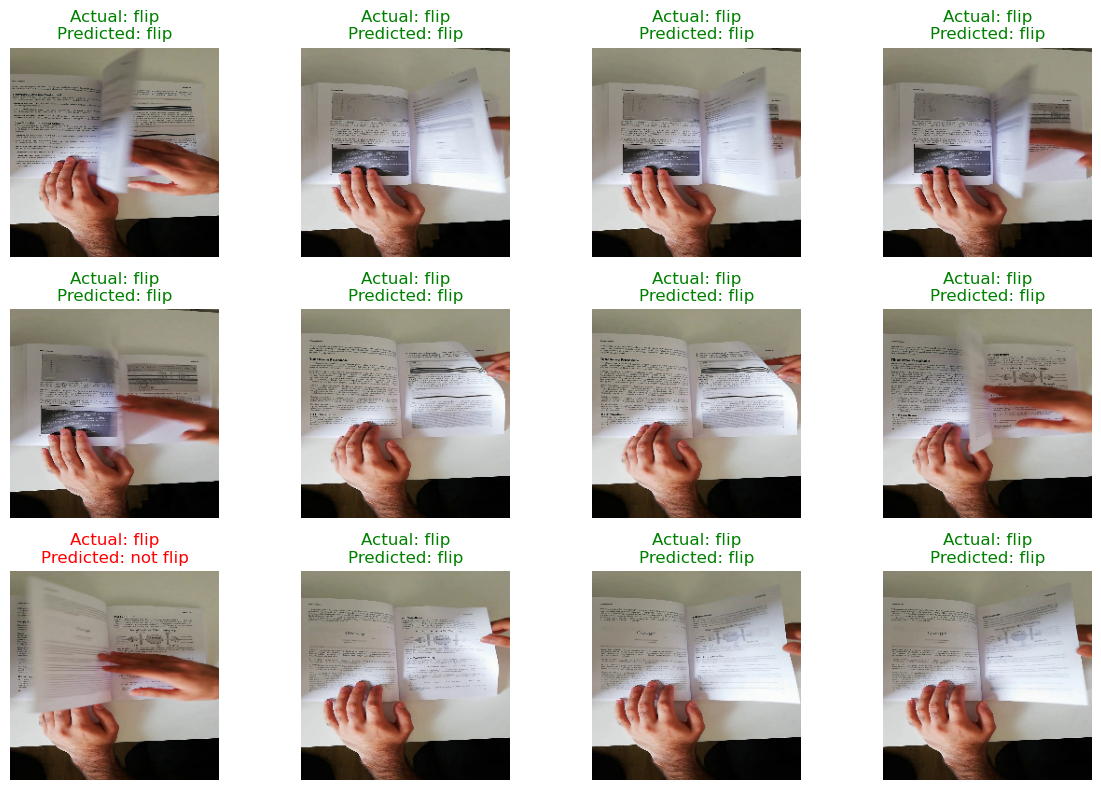

In [27]:
import matplotlib.pyplot as plt

class_names = ["flip", "not flip"]  # Must match your dataset's class order

for images, labels in test_dataset.take(1):
    probabilities = model.predict(images, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    plt.figure(figsize=(12, 8))

    for i in range(min(12, len(images))):
        actual = int(labels[i].numpy().item())
        predicted = predictions[i]

        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(
            f"Actual: {class_names[actual]}\n"
            f"Predicted: {class_names[predicted]}",
            color="green" if actual == predicted else "red"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

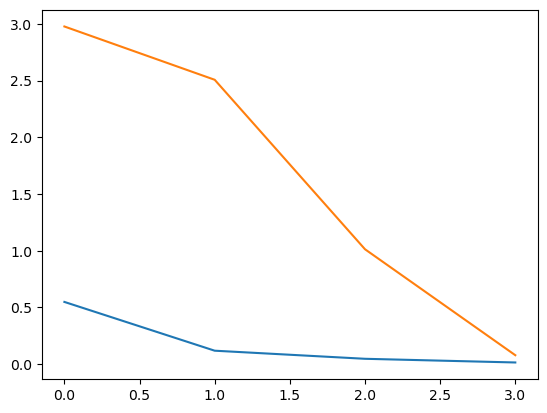

In [26]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.show()

In [ ]:
# Data augmentation mild setup
# the idea the images are too large therefore resizing required 

data_augmentation = tf.keras.Sequential([
    #tf.keras.layers.RandomFlip("horizontal"),
    #tf.keras.layers.RandomRotation(0.02),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(factor=0.1)
])


def load_small_image(file):
    with Image.open(file) as img:
        return np.array(
            img.convert("RGB").resize((224, 224)),
            dtype="float32"
        )
    
    

augmented_images = [
    data_augmentation(load_small_image(file), training=True)
    for file in train_files
]